# Spin-Glass Benchmarks: tutorial

This notebook shows how to use the repository to:

1. read the benchmark instances committed to the repository;
2. download further instances from the Hugging Face dataset;
3. run the benchmark solvers (zero-temperature descents and annealing methods) through their command-line entry points;
4. reproduce published results for one instance and compare them with the [Results](https://ocadni.github.io/spin-glass-benchmarks/results.html) tables.

The notebook only calls the generic entry points of the repository:

| Entry point | Purpose |
|---|---|
| `instances/download_instances.py` | Download instances from the Hugging Face dataset |
| `experiments/sapienza/code/annealing_solvers/Modern/optimization/solver.py` | Simulated, population, and global annealing (`sa`, `pa`, `ga`) |
| `experiments/sapienza/code/greedy_solvers/greedy.c` | Zero-temperature descents (`greedy`, `reluctant`, `random`) |

The algorithms are listed on the [Algorithms](https://ocadni.github.io/spin-glass-benchmarks/algorithms.html) page; the ones run here are described in [`experiments/sapienza/README.md`](../experiments/sapienza/README.md), and the problem families on the [Problem Definition](https://ocadni.github.io/spin-glass-benchmarks/problem_definition.html) page.

**Environment.** Create one of the solver environments described in the repository README (for example `conda env create -f environments/solvers-core-cpu.yml`), then install the notebook dependencies in it:

```bash
pip install jupyter matplotlib huggingface_hub
```

The descents are written in C and require a C compiler (`cc`). A GPU is optional: the annealing solvers use CUDA or Apple MPS automatically when available.

## Setup

The cell below locates the repository and defines thin wrappers around the three entry points. Each wrapper prints the equivalent shell command, so every step of the notebook can also be run from a terminal.

In [1]:
import json
import math
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until the repository root is found."""
    for path in (start, *start.parents):
        if (path / "instances" / "download_instances.py").is_file():
            return path
    raise FileNotFoundError("run this notebook from inside the spin-glass-benchmarks repository")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
INSTANCES_DIR = REPO_ROOT / "instances"
DOWNLOAD_SCRIPT = INSTANCES_DIR / "download_instances.py"
SOLVER_SCRIPT = (REPO_ROOT / "experiments" / "sapienza" / "code" / "annealing_solvers"
                 / "Modern" / "optimization" / "solver.py")
GREEDY_SOURCE = REPO_ROOT / "experiments" / "sapienza" / "code" / "greedy_solvers" / "greedy.c"
RESULTS_DIR = REPO_ROOT / "experiments" / "sapienza" / "results"


DISPLAY_NAMES = {sys.executable: "python"}  # shorter names for printed commands


def as_argument(value) -> str:
    """Convert a value to a command-line argument; repository paths become relative."""
    if isinstance(value, Path) and value.is_relative_to(REPO_ROOT):
        return str(value.relative_to(REPO_ROOT))
    return str(value)


def run_command(args, echo: bool = True) -> str:
    """Run a command from the repository root, raise on failure, and return its output."""
    args = [as_argument(a) for a in args]
    if echo:
        print("$", " ".join(DISPLAY_NAMES.get(a, a) for a in args))
    result = subprocess.run(args, capture_output=True, text=True, cwd=REPO_ROOT)
    if result.returncode != 0:
        raise RuntimeError(f"command failed ({result.returncode}):\n{result.stderr}")
    return result.stdout.replace(str(REPO_ROOT), ".")


def download_instances(*options: str) -> str:
    """Call instances/download_instances.py with command-line options."""
    return run_command([sys.executable, DOWNLOAD_SCRIPT, *options])


def run_annealer(instance: Path, annealer: str, echo: bool = True, **options) -> dict:
    """Call solver.py and return its JSON summary.

    Keyword arguments map to command-line options: population_size=1000
    becomes --population-size 1000, and quench=True becomes --quench.
    """
    args = [sys.executable, SOLVER_SCRIPT, instance, annealer, "--json"]
    for name, value in options.items():
        flag = "--" + name.replace("_", "-")
        if value is True:
            args.append(flag)
        elif value is not False and value is not None:
            args += [flag, value]
    return json.loads(run_command(args, echo=echo))


print("repository found:", REPO_ROOT.name)

repository found: spin-glass-benchmarks


The descents are compiled once into a temporary directory, with the same flags used by the repository run scripts. 

In [2]:
GREEDY_BINARY = Path(tempfile.mkdtemp()) / "greedy"
DISPLAY_NAMES[str(GREEDY_BINARY)] = "greedy"
compiler = shutil.which("cc") or shutil.which("gcc") or shutil.which("clang")
if compiler is None:
    raise RuntimeError("a C compiler (cc, gcc, or clang) is required for the descents")
DISPLAY_NAMES[compiler] = Path(compiler).name
run_command([compiler, "-O3", "-std=c11", GREEDY_SOURCE, "-lm", "-o", GREEDY_BINARY])

DESCENT_COLUMNS = ["mean_flips", "N", "instance_seed", "run_seed",
                   "min_energy_per_spin", "elapsed_seconds"]


def run_descent(instance: Path, mode: str, seed: int, num_spins: int,
                instance_seed: int, echo: bool = True) -> dict:
    """Run one zero-temperature descent and return its result row as a dict."""
    output = run_command([
        GREEDY_BINARY, instance,
        "--num-spins", num_spins,
        "--instance-seed", instance_seed,
        "--mode", mode,
        "--pop-size", 1,
        "--sweeps", 100_000_000,   # effectively unlimited: run to a local minimum
        "--seed", seed,
    ], echo=echo)
    values = output.split()
    return {name: float(value) for name, value in zip(DESCENT_COLUMNS, values)}

$ cc -O3 -std=c11 experiments/sapienza/code/greedy_solvers/greedy.c -lm -o greedy


## Benchmark instances

### Instances committed to the repository

The repository contains the first five instances of every family and size. They are stored under `instances/<family>/N<N>/`, with the file name `<family>_couplings_N<N>_J<mean>_seed<seed>.txt`.

In [3]:
committed = sorted(INSTANCES_DIR.glob("*/N*/*_couplings_*.txt"))
inventory = pd.DataFrame({
    "family": [p.parts[-3] for p in committed],
    "N": [int(p.parts[-2][1:]) for p in committed],
})
inventory.value_counts().rename("files").sort_index().to_frame()

files
family N          
ea3d   1000      5
       2744      5
sk     50        6
       100       5
       200       5
       300       5
       400       5
       600       5
       800       5
       1000      5
       1200      5
       1400      5
       1600      5
       2000      5

### File format

Each file starts with a `#` metadata line. It is followed by `num_fields` lines `i h_i` giving the external fields, and then by one line `i j J_ij` per coupling, with zero-based spin indices. For the SK model, the $1/\sqrt{N}$ normalization is already included in $J_{ij}$. The full specification is on the [File Format](https://ocadni.github.io/spin-glass-benchmarks/file_format.html) page.

In [4]:
sk_instance = INSTANCES_DIR / "sk" / "N50" / "sk_couplings_N50_J0_seed1051732.txt"
lines = sk_instance.read_text().splitlines()
print("\n".join(lines[:3]))
print("...")
print("\n".join(lines[50:54]))
print("...")

# model=sk N=50 meanJ=0 seed=1051732 distribution=gaussian field=0 num_fields=50 num_couplings=1225
0 0
1 0
...
49 0
0 1 -0.04149
0 2 -0.13652
0 3 -0.10429
...


### Loading an instance

`read_couplings`, the loader used by `solver.py`, returns the symmetric coupling matrix $J$ and the external fields $h$ (`None` when all fields are zero). It is imported here through `solver.py`.

In [5]:
sys.path.insert(0, str(SOLVER_SCRIPT.parent))
from solver import read_couplings  # noqa: E402

J, h = read_couplings(sk_instance, return_fields=True)
J = J.numpy()
print("N =", J.shape[0])
print("external fields:", "none" if h is None else "present")
print("symmetric:", np.allclose(J, J.T))
print("couplings per spin:", int((J != 0).sum(axis=1).mean()))

N = 50
external fields: none
symmetric: True
couplings per spin: 49


The energy of a configuration $\mathbf{s} \in \{-1,+1\}^N$ is $H(\mathbf{s}) = -\tfrac12\, \mathbf{s}^\top J \mathbf{s} - \mathbf{h}^\top \mathbf{s}$. All energies reported by the solvers and in the Results tables are energies per spin, $H/N$.

In [6]:
def energy_per_spin(s, J, h=None):
    energy = -0.5 * s @ J @ s
    if h is not None:
        energy -= h @ s
    return energy / len(s)


rng = np.random.default_rng(0)
random_energies = [energy_per_spin(rng.choice([-1, 1], size=J.shape[0]), J) for _ in range(1000)]
print(f"random configurations: mean energy per spin = {np.mean(random_energies):+.4f}, "
      f"lowest = {np.min(random_energies):+.4f}")

random configurations: mean energy per spin = -0.0062, lowest = -0.3090


### Downloading instances from Hugging Face

All instances (100 per SK size, and the full EA3D sets) are hosted on the Hugging Face Hub. `download_instances.py --info` lists what is available without downloading anything.

In [7]:
print(download_instances("--info"))

$ python instances/download_instances.py --info


ea3d: 410 instance(s)
  N512: 100 seed(s)
  N1000: 200 seed(s)
  N1728: 100 seed(s)
  N2744: 10 seed(s)
sk: 1200 instance(s)
  N50: 100 seed(s)
  N100: 100 seed(s)
  N200: 100 seed(s)
  N300: 100 seed(s)
  N400: 100 seed(s)
  N600: 100 seed(s)
  N800: 100 seed(s)
  N1000: 100 seed(s)
  N1200: 100 seed(s)
  N1400: 100 seed(s)
  N1600: 100 seed(s)
  N2000: 100 seed(s)



An instance is selected by family, size, and seed. Downloaded files are written to `instances/<family>/N<N>/`, next to the committed ones, and are ignored by git. Other selections follow the same pattern:

| Command options | Downloads |
|---|---|
| `--type sk --N 50 --seed 1051747` | one instance |
| `--type sk --N 50` | every seed of one size |
| `--type ea3d` | every size of one family |
| `--type all` | the full dataset |

In [8]:
print(download_instances("--type", "sk", "--N", "50", "--seed", "1051747"))

downloaded = INSTANCES_DIR / "sk" / "N50" / "sk_couplings_N50_J0_seed1051747.txt"
J_downloaded, _ = read_couplings(downloaded, return_fields=True)
print(downloaded.name, "loaded:", tuple(J_downloaded.shape))

$ python instances/download_instances.py --type sk --N 50 --seed 1051747


Downloaded to ./instances

sk_couplings_N50_J0_seed1051747.txt loaded: (50, 50)


## Running the solvers

### Zero-temperature descents

A descent starts from a random configuration and flips unsatisfied spins until it reaches a local minimum. The selection rule (`greedy`, `reluctant`, or `random`) chooses which spin is flipped at each step. Each call prints one row: the number of flips, the instance, the run seed, the final energy per spin, and the running time in seconds.

In [9]:
for mode in ("greedy", "reluctant", "random"):
    row = run_descent(sk_instance, mode, seed=1, num_spins=50, instance_seed=1051732)
    print(f"  -> {row['mean_flips']:.0f} flips, energy per spin {row['min_energy_per_spin']:+.6f}\n")

$ greedy instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt --num-spins 50 --instance-seed 1051732 --mode greedy --pop-size 1 --sweeps 100000000 --seed 1
  -> 28 flips, energy per spin -0.658503

$ greedy instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt --num-spins 50 --instance-seed 1051732 --mode reluctant --pop-size 1 --sweeps 100000000 --seed 1
  -> 217 flips, energy per spin -0.605834

$ greedy instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt --num-spins 50 --instance-seed 1051732 --mode random --pop-size 1 --sweeps 100000000 --seed 1
  -> 24 flips, energy per spin -0.559030



### Annealing methods

`solver.py` runs simulated annealing (`sa`), population annealing (`pa`), or global annealing (`ga`) on any instance file. Its main options are:

| Option | Meaning |
|---|---|
| `--population-size` | number of replicas $R$ |
| `--num-temps`, `--t-start`, `--t-end`, `--schedule` | temperature schedule (`linearT`, `linearBeta`, or `logT`) |
| `--num-steps-mc` | Metropolis sweeps per temperature (SA, PA); global moves per temperature (GA) |
| `--swap-step` | Metropolis sweeps after each global move (GA only) |
| `--thermalization-steps` | sweeps at $T_{\mathrm{start}}$ before annealing |
| `--quench` | quench the final population at $T = 0$ |
| `--device`, `--seed` | `auto`, `cpu`, `cuda`, or `mps`; random seed |

With `--json`, the solver returns a summary of the run.

In [10]:
summary = run_annealer(
    sk_instance, "pa",
    population_size=1000, num_steps_mc=10, num_temps=10,
    t_start=1.5, t_end=0.1, schedule="logT",
    thermalization_steps=50, quench=True, seed=1,
)
summary

$ python experiments/sapienza/code/annealing_solvers/Modern/optimization/solver.py instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt pa --json --population-size 1000 --num-steps-mc 10 --num-temps 10 --t-start 1.5 --t-end 0.1 --schedule logT --thermalization-steps 50 --quench --seed 1


{'annealer': 'pa',
 'best_min_energy_per_spin': -0.666784,
 'device': 'cuda',
 'elapsed_seconds': 1.1256682872772217,
 'final_min_energy_per_spin': -0.666784,
 'has_external_fields': False,
 'instance': 'instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt',
 'num_spins': 50,
 'num_temperatures': 10,
 'quench_converged': True,
 'quench_mean_energy_per_spin': -0.666542,
 'quench_min_energy_per_spin': -0.666784,
 'quench_seconds': 0.031272172927856445,
 'quench_sweeps': 2,
 't_end': 0.1,
 't_start': 1.5,
 'thermalization_seconds': 0.7545416355133057,
 'total_elapsed_seconds': 1.8802099227905273}

The energy of a run is the lower of `best_min_energy_per_spin` (lowest energy during the anneal) and `quench_min_energy_per_spin` (lowest energy after the final quench). Its running time is `total_elapsed_seconds` plus `quench_seconds`; for global annealing, the total already includes the training of the network.

## Reproducing published results: SK, $N = 50$

This section repeats the benchmark protocol on one SK instance and compares the outcome with the published rows in `experiments/sapienza/results/sk/summary.csv`.

### Published results

For SK, the reference energy of an instance is the lowest energy found by any algorithm, and a run succeeds if its energy is within $1.5 \times 10^{-6}$ per spin of the reference. The time to solution is
$\mathrm{TTS}_{0.99} = \bar{t}\,\log(1-0.99)/\log(1-P_s)$, where $\bar t$ is the mean running time of one run and $P_s$ the success probability.

In [11]:
N, SEED = 50, 1051732
instance = INSTANCES_DIR / "sk" / f"N{N}" / f"sk_couplings_N{N}_J0_seed{SEED}.txt"

published = pd.read_csv(RESULTS_DIR / "sk" / "summary.csv")
published = published[(published.N == N) & (published.seed == SEED)].set_index("program_name")
REFERENCE = published.min_energy.min()
TOLERANCE = 1.5e-6
print(f"reference energy per spin: {REFERENCE:.8f}")
published[["min_energy", "success_probability", "average_time", "TTS", "hardware"]]

reference energy per spin: -0.66678400


,min_energy,success_probability,average_time,TTS,hardware
program_name,,,,,
Greedy,-0.666784,0.032,0.000530,0.074531,Intel Xeon Gold 6248
Random,-0.666784,0.042,0.000568,0.060480,Intel Xeon Gold 6248
Reluctant,-0.666784,0.059,0.000262,0.019938,Intel Xeon Gold 6248
Global Annealing,-0.666784,1.000,13.046608,13.046608,NVIDIA Tesla V100-SXM2-32G
Population Annealing,-0.666784,1.000,0.636708,0.636708,NVIDIA Tesla V100-SXM2-32G
Simulated Annealing,-0.666784,1.000,0.714981,0.714981,NVIDIA Tesla V100-SXM2-32G


In [12]:
def time_to_solution(mean_time: float, success_probability: float, target: float = 0.99) -> float:
    if success_probability <= 0:
        return math.inf
    if success_probability >= 1:
        return mean_time
    return mean_time * math.log1p(-target) / math.log1p(-success_probability)


def summarize(name: str, energies, times) -> dict:
    energies, times = np.asarray(energies), np.asarray(times)
    success = float(np.mean(energies <= REFERENCE + TOLERANCE))
    return {
        "program_name": name,
        "runs": len(energies),
        "min_energy": energies.min(),
        "success_probability": success,
        "average_time": times.mean(),
        "TTS": time_to_solution(times.mean(), success),
    }

### Zero-temperature descents

Each descent is cheap, so many independent runs are needed to estimate its success probability. The published rows use 1000 runs per instance. Only the first command is printed.

In [13]:
DESCENT_RUNS = 1000
DESCENT_NAMES = {"greedy": "Greedy", "reluctant": "Reluctant", "random": "Random"}

descent_energies = {}
reproduced = []
for mode, name in DESCENT_NAMES.items():
    rows = [run_descent(instance, mode, seed=s, num_spins=N, instance_seed=SEED, echo=(s == 0))
            for s in range(DESCENT_RUNS)]
    energies = [r["min_energy_per_spin"] for r in rows]
    descent_energies[name] = energies
    reproduced.append(summarize(name, energies, [r["elapsed_seconds"] for r in rows]))

pd.DataFrame(reproduced).set_index("program_name")

$ greedy instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt --num-spins 50 --instance-seed 1051732 --mode greedy --pop-size 1 --sweeps 100000000 --seed 0


$ greedy instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt --num-spins 50 --instance-seed 1051732 --mode reluctant --pop-size 1 --sweeps 100000000 --seed 0


$ greedy instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt --num-spins 50 --instance-seed 1051732 --mode random --pop-size 1 --sweeps 100000000 --seed 0


,runs,min_energy,success_probability,average_time,TTS
program_name,,,,,
Greedy,1000,-0.666784,0.026,0.000018,0.003082
Reluctant,1000,-0.666784,0.069,0.000205,0.013173
Random,1000,-0.666784,0.036,0.000017,0.002090


The cumulative distribution of the final energies shows the fraction of runs that end at or below each energy. Its value at the reference energy is the success probability, and its spread shows how far the typical local minima reached by each rule lie above the reference.

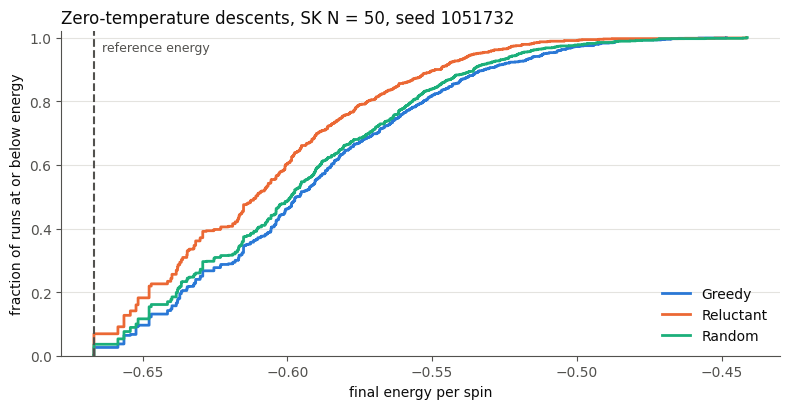

In [14]:
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, MUTED_INK, GRID = "#0b0b0b", "#52514e", "#e4e3df"


def plot_descent_energies(energies_by_rule: dict, reference: float, reference_label: str, title: str):
    """Plot the cumulative distribution of final energies for each selection rule."""
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for color, (name, energies) in zip(SERIES_COLORS, energies_by_rule.items()):
        values = np.sort(energies)
        fraction = np.arange(1, len(values) + 1) / len(values)
        ax.step(np.r_[reference, values], np.r_[0, fraction], where="post",
                linewidth=2, color=color, label=name)
    ax.axvline(reference, color=MUTED_INK, linewidth=1.5, linestyle="--")
    ax.annotate(reference_label, xy=(reference, 1), xycoords=("data", "axes fraction"),
                xytext=(6, -14), textcoords="offset points", color=MUTED_INK, fontsize=9)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("final energy per spin", color=INK)
    ax.set_ylabel("fraction of runs at or below energy", color=INK)
    ax.set_title(title, loc="left", color=INK)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED_INK)
    ax.tick_params(colors=MUTED_INK)
    ax.legend(frameon=False, labelcolor=INK, loc="lower right")
    fig.tight_layout()
    plt.show()


plot_descent_energies(descent_energies, REFERENCE, "reference energy",
                      f"Zero-temperature descents, SK N = {N}, seed {SEED}")

### Annealing methods

The published SK runs use the parameters below, with $R = 10^5$ replicas and 10 runs per instance on an NVIDIA V100 GPU. The defaults here use $R = 10^4$ and 3 runs, which take about two minutes on a laptop CPU. Set `POPULATION_SIZE = 100_000` and `ANNEALING_RUNS = 10` to repeat the published protocol exactly.

In [15]:
POPULATION_SIZE = 10_000
ANNEALING_RUNS = 3

COMMON = dict(population_size=POPULATION_SIZE, t_start=1.5, t_end=0.1, schedule="logT",
              thermalization_steps=50, quench=True)
SETTINGS = {  # published settings for N <= 800 (see the SK notes on the Results page)
    "Simulated Annealing": ("sa", dict(num_temps=100, num_steps_mc=1)),
    "Population Annealing": ("pa", dict(num_temps=10, num_steps_mc=10)),
    "Global Annealing": ("ga", dict(num_temps=10, num_steps_mc=5, swap_step=15)),
}

for name, (annealer, options) in SETTINGS.items():
    energies, times = [], []
    for run in range(ANNEALING_RUNS):
        result = run_annealer(instance, annealer, echo=(run == 0), seed=run, **COMMON, **options)
        energies.append(min(result["best_min_energy_per_spin"], result["quench_min_energy_per_spin"]))
        times.append(result["total_elapsed_seconds"] + result["quench_seconds"])
    reproduced.append(summarize(name, energies, times))
    print(f"  -> {name}: lowest energy per spin {min(energies):+.6f}\n")

$ python experiments/sapienza/code/annealing_solvers/Modern/optimization/solver.py instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt sa --json --seed 0 --population-size 10000 --t-start 1.5 --t-end 0.1 --schedule logT --thermalization-steps 50 --quench --num-temps 100 --num-steps-mc 1


  -> Simulated Annealing: lowest energy per spin -0.666784

$ python experiments/sapienza/code/annealing_solvers/Modern/optimization/solver.py instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt pa --json --seed 0 --population-size 10000 --t-start 1.5 --t-end 0.1 --schedule logT --thermalization-steps 50 --quench --num-temps 10 --num-steps-mc 10


  -> Population Annealing: lowest energy per spin -0.666784

$ python experiments/sapienza/code/annealing_solvers/Modern/optimization/solver.py instances/sk/N50/sk_couplings_N50_J0_seed1051732.txt ga --json --seed 0 --population-size 10000 --t-start 1.5 --t-end 0.1 --schedule logT --thermalization-steps 50 --quench --num-temps 10 --num-steps-mc 5 --swap-step 15


  -> Global Annealing: lowest energy per spin -0.666784



### Comparison

The energies and success probabilities can be compared directly with the published values. Running times and TTS depend on the hardware and on the population size, so they are comparable only when the published protocol and hardware are used.

In [16]:
reproduced_table = pd.DataFrame(reproduced).set_index("program_name")
comparison = pd.DataFrame({
    "published energy": published.min_energy,
    "reproduced energy": reproduced_table.min_energy,
    "published P_s": published.success_probability,
    "reproduced P_s": reproduced_table.success_probability,
    "published TTS (s)": published.TTS,
    "reproduced TTS (s)": reproduced_table.TTS,
}).loc[list(reproduced_table.index)]
comparison

,published energy,reproduced energy,published P_s,reproduced P_s,published TTS (s),reproduced TTS (s)
program_name,,,,,,
Greedy,-0.666784,-0.666784,0.032,0.026,0.074531,0.003082
Reluctant,-0.666784,-0.666784,0.059,0.069,0.019938,0.013173
Random,-0.666784,-0.666784,0.042,0.036,0.060480,0.002090
Simulated Annealing,-0.666784,-0.666784,1.000,1.000,0.714981,2.325429
Population Annealing,-0.666784,-0.666784,1.000,1.000,0.636708,2.003619
Global Annealing,-0.666784,-0.666784,1.000,1.000,13.046608,13.254149


## Comparison with a reference energy: EA3D, $N = 1000$

For the EA3D instances with $N = 1000$, the repository provides one reference energy per instance in `instances/verified_gs/ea3d/N1000/energies.csv`. Comparing a solver's best energy with this reference measures how far each method stops from it.

In [17]:
reference_energies = pd.read_csv(INSTANCES_DIR / "verified_gs" / "ea3d" / "N1000" / "energies.csv")
EA_N, EA_SEED = 1000, 110046
ea_instance = INSTANCES_DIR / "ea3d" / f"N{EA_N}" / f"ea3d_couplings_N{EA_N}_J0_seed{EA_SEED}.txt"
EA_REFERENCE = reference_energies.set_index("seed").energy[EA_SEED]
print(f"reference energy per spin: {EA_REFERENCE:.5f}")

reference energy per spin: -1.65216


$ greedy instances/ea3d/N1000/ea3d_couplings_N1000_J0_seed110046.txt --num-spins 1000 --instance-seed 110046 --mode greedy --pop-size 1 --sweeps 100000000 --seed 0


$ greedy instances/ea3d/N1000/ea3d_couplings_N1000_J0_seed110046.txt --num-spins 1000 --instance-seed 110046 --mode reluctant --pop-size 1 --sweeps 100000000 --seed 0


$ greedy instances/ea3d/N1000/ea3d_couplings_N1000_J0_seed110046.txt --num-spins 1000 --instance-seed 110046 --mode random --pop-size 1 --sweeps 100000000 --seed 0


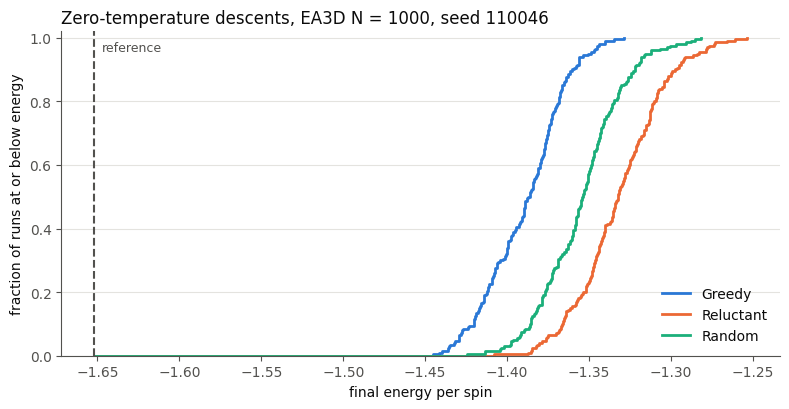

In [18]:
EA_DESCENT_RUNS = 200
ea_descent_energies = {
    name: [run_descent(ea_instance, mode, seed=s, num_spins=EA_N, instance_seed=EA_SEED,
                       echo=(s == 0))["min_energy_per_spin"]
           for s in range(EA_DESCENT_RUNS)]
    for mode, name in DESCENT_NAMES.items()
}
plot_descent_energies(ea_descent_energies, EA_REFERENCE, "reference",
                      f"Zero-temperature descents, EA3D N = {EA_N}, seed {EA_SEED}")

On EA3D, the descents stop far above the reference energy, and the ranking of the selection rules differs from SK: on this instance greedy descent reaches the lowest energies and reluctant descent the highest, as in the published rows. Reaching the reference energy requires an annealing method run at the published scale: population annealing with $R = 10^5$ replicas and 40 temperatures reaches it in about 20 seconds on a V100 GPU, but takes several minutes on a CPU. The cell below is therefore disabled by default; set `RUN_EA3D_ANNEALING = True` to run it.

In [19]:
RUN_EA3D_ANNEALING = False

if RUN_EA3D_ANNEALING:
    result = run_annealer(ea_instance, "pa", population_size=100_000, num_temps=40,
                          num_steps_mc=10, t_start=1.5, t_end=0.1, schedule="logT",
                          thermalization_steps=50, quench=True, seed=0)
    energy = min(result["best_min_energy_per_spin"], result["quench_min_energy_per_spin"])
    print(f"population annealing: {energy:+.5f}  (reference {EA_REFERENCE:+.5f}, "
          f"gap {energy - EA_REFERENCE:.5f})")